<a href="https://colab.research.google.com/github/santana-robledo/Posgrado_Robotica_e_Inteligencia_Artificial/blob/main/Vision_Artificial/07.%20LenguajeSe%C3%B1asChallenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Bibliotecas para creación de redes neuronales profundas
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, Flatten, Dropout, MaxPooling2D, Flatten, AveragePooling2D
from tensorflow.keras import optimizers, backend, callbacks
import tensorflow.keras.utils as np_utils
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(100)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Lectura del archivo de imágenes
dataset = pd.read_csv('/content/drive/MyDrive/SenasDataset.csv',
                      header = None)
dataset

,0,1,2,3,4,5,6,7,8,9,...,1591,1592,1593,1594,1595,1596,1597,1598,1599,1600
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,255.0,255.0,255.0,255.0,255.0,135.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,32.0,223.0,255.0,255.0,255.0,255.0,255.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,82.0,51.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,16.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0
11996,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0
11997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40.0,159.0,255.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0
11998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,251.0,255.0,239.0,104.0,0.0,0.0,0.0,0.0,0.0,23.0


In [ ]:
# Tamaño de los datos
dataset.shape

(12000, 1601)

## Pre-procesamiento de los datos

In [ ]:
# Cambio del tipo de dato del data set a arreglo de numpy
dataset = dataset.values

In [ ]:
# Separar imágenes y etiquetas
imagenes = dataset[:,:-1]
clases = dataset[:,-1]

In [ ]:
imagenes.shape

(12000, 1600)

In [ ]:
# Transformar imágenes a su formato original
imagenes = imagenes.reshape(12000, 40, 40, 1)

In [ ]:
# Escalamiento de las imágenes
imagenes = imagenes/255

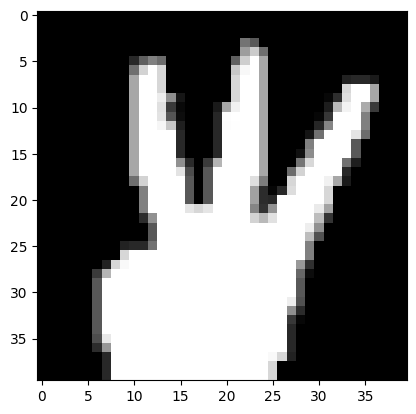

20.0


In [ ]:
# Visualización de las imágenes
plt.imshow(imagenes[10000], cmap = 'gray')
plt.show()

print(clases[10000])

In [ ]:
# Codificación 1-hot de las etiquetas
etiquetas = np_utils.to_categorical(clases)

In [ ]:
# Construcción de los conjuntos de entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(imagenes, etiquetas,
                                                    test_size = 0.20, random_state = 100)

In [ ]:
print(x_test.shape)
print(y_test.shape)
print(x_train.shape)
print(y_train.shape)

(2400, 40, 40, 1)
(2400, 24)
(9600, 40, 40, 1)
(9600, 24)


## Diseño y entrenamiento del modelo

In [ ]:
backend.clear_session()

In [ ]:
# Construcción del modelo

modelo = Sequential()
modelo.add(Input(shape = (40, 40, 1)))
modelo.add(Conv2D(32, kernel_size = (3,3), activation = 'relu'))
modelo.add(AveragePooling2D(pool_size = (2,2)))
modelo.add(Conv2D(64, kernel_size = (3,3), activation = 'relu'))
modelo.add(AveragePooling2D(pool_size = (2,2)))
modelo.add(Conv2D(128, kernel_size = (3,3), activation = 'relu'))
modelo.add(AveragePooling2D(pool_size = (2,2)))
modelo.add(Flatten())
modelo.add(Dense(70, activation = 'relu'))
modelo.add(Dense(40, activation = 'relu'))
modelo.add(Dense(24, activation = 'softmax'))

modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 38, 38, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 19, 19, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 17, 17, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 8, 8, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 6, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 3, 3, 128)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 70)             │        80,710 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         2,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │           984 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,206 (692.21 KB)

 Trainable params: 177,206 (692.21 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Optimizador y compilación del modelo
adam = optimizers.Adam(learning_rate = 0.001)
modelo.compile(loss = 'categorical_crossentropy', optimizer = adam, metrics = ['accuracy'])

In [ ]:
#Checkpointer para guardar el mejor modelo
checkpointer = callbacks.ModelCheckpoint('lenguajeSenas.keras', monitor = 'val_accuracy',
                                         save_best_only = True, mode = 'max',
                                         verbose = True)

In [ ]:
# Entrenamiento del modelo
M = modelo.fit(x_train, y_train,
               validation_data = (x_test, y_test),
               epochs = 30,
               callbacks = [checkpointer],
               verbose = True)

Epoch 1/30
288/300 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0971 - loss: 2.9784
Epoch 1: val_accuracy improved from None to 0.26250, saving model to lenguajeSenas.keras

Epoch 1: finished saving model to lenguajeSenas.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.1603 - loss: 2.7061 - val_accuracy: 0.2625 - val_loss: 2.3263
Epoch 2/30
287/300 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3055 - loss: 2.0996
Epoch 2: val_accuracy improved from 0.26250 to 0.47208, saving model to lenguajeSenas.keras

Epoch 2: finished saving model to lenguajeSenas.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3656 - loss: 1.8860 - val_accuracy: 0.4721 - val_loss: 1.5726
Epoch 3/30
292/300 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5130 - loss: 1.4472
Epoch 3: val_accuracy improved from 0.47208 to 0.60000, saving model to lenguajeSenas.keras

Epoch 3: finished saving model to lenguajeSenas.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5494 - loss: 1.

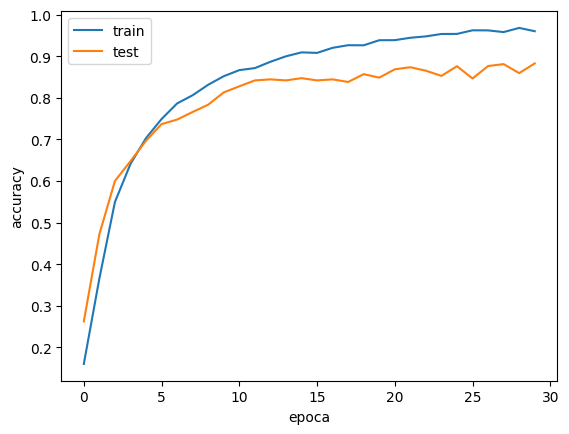

In [ ]:
# Evaluación del modelo
plt.plot(M.history['accuracy'], label = 'train')
plt.plot(M.history['val_accuracy'], label = 'test')
plt.legend(loc = 'best')
plt.xlabel('epoca')
plt.ylabel('accuracy')
plt.show()

## Prueba del modelo

In [ ]:
# Diccionario para determinar la letra a partir del valor de clasificación
clase2letra = {0: 'a', 1: 'b', 2: 'c', 3: 'd', 4: 'e', 5: 'f', 6: 'g', 7: 'h', 8: 'i', 9: 'l', 10: 'm', 11: 'n', 12: 'o', 13: 'p', 14: 'q', 15: 'r', 16: 's', 17: 't', 18: 'u', 19: 'v', 20: 'w', 21: 'x', 22: 'y', 23: 'z'}

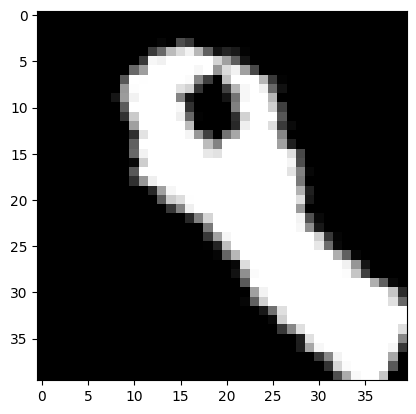

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 815ms/step
Predicción =  o
Real =  o


In [ ]:
# Prueba con imágenes del subconjunto de test
n = 300
plt.imshow(x_test[n].reshape(40,40), cmap='gray')
plt.show()

letra = modelo.predict(x_test[n].reshape(1,40,40,1))

print('Predicción = ', clase2letra[np.argmax(letra)])
print('Real = ', clase2letra[np.argmax(y_test[n])])

## Pruebas con otras imágenes

In [ ]:
modelo.load_weights('lenguajeSenas.keras')

In [ ]:
import cv2

(510, 459, 3)


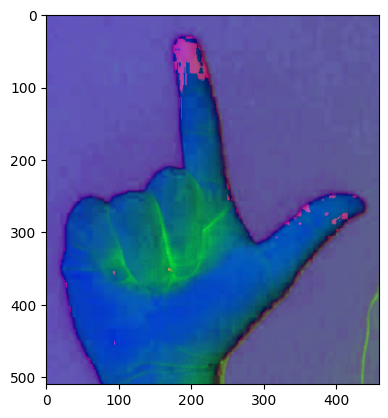

In [ ]:
# Lectura de la imagen mediante opencv
mano = cv2.imread('l_1.jpg')
manoHSV = cv2.cvtColor(mano, cv2.COLOR_BGR2HSV)
manoHSV = manoHSV[110:620]
print(manoHSV.shape)
plt.imshow(manoHSV, cmap='hsv')
plt.show()

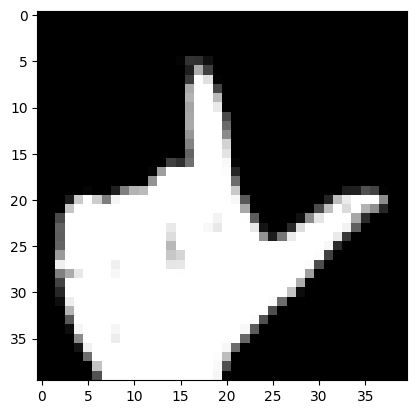

In [ ]:
# Segmentación de la mano
manoBin = np.zeros((manoHSV.shape[0], manoHSV.shape[1]))
for i in range(manoHSV.shape[0]):
  for j in range(manoHSV.shape[1]):
    if (manoHSV[i,j,0] >= 0 and manoHSV[i,j,0] <= 20) \
    and (manoHSV[i,j,1] >= 50 and manoHSV[i,j,1] <= 200)\
    and (manoHSV[i,j,2] >= 10 and manoHSV[i,j,2] <= 230):
      manoBin[i,j] = 1

# Erosión, dilatación y redimensionamiento
kernel = np.ones((3,3))
manoEro = cv2.erode(manoBin, kernel, iterations = 1)
manoDil = cv2.dilate(manoEro, kernel, iterations = 1)
manoRes = cv2.resize(manoDil, (40,40), interpolation = cv2.INTER_AREA)
plt.imshow(manoRes, cmap='gray')
plt.show()

In [ ]:
# Predicción/Inferencia
manoRes = (manoRes - np.amin(manoRes))/(np.amax(manoRes) - np.amin(manoRes))
letra = modelo.predict(manoRes.reshape(1,40,40,1))
print('Predicción = ', np.argmax(letra))
print('Letra = ', clase2letra[np.argmax(letra)])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Predicción =  9
Letra =  l
